In [1]:
pip install tensorflow pandas scikit-learn numpy


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


DEPRECATION: Loading egg at c:\program files\python311\lib\site-packages\vboxapi-1.0-py3.11.egg is deprecated. pip 24.3 will enforce this behaviour change. A possible replacement is to use pip for package installation.. Discussion can be found at https://github.com/pypa/pip/issues/12330

[notice] A new release of pip is available: 23.3.1 -> 25.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder, MinMaxScaler

# Load dataset
df = pd.read_csv("retail_store_inventory (1).csv")  # Update with your actual file path

# Convert Date column to datetime
df['Date'] = pd.to_datetime(df['Date'])

# Sorting by Date (important for time series)
df = df.sort_values(by=['Date'])

# Encode categorical columns
cat_cols = ['Store ID', 'Product ID', 'Category', 'Region', 'Weather Condition', 'Seasonality']
label_encoders = {}

for col in cat_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])
    label_encoders[col] = le  # Store encoders for later use

# Normalize numerical columns
num_cols = ['Inventory Level', 'Units Sold', 'Units Ordered', 'Demand Forecast', 'Price', 'Discount', 'Competitor Pricing']
scaler = MinMaxScaler()
df[num_cols] = scaler.fit_transform(df[num_cols])

print("✅ Data Preprocessing Done!")
print(df.head())


✅ Data Preprocessing Done!
         Date  Store ID  Product ID  Category  Region  Inventory Level  \
0  2022-01-01         0           0         3       1         0.402222   
72 2022-01-01         3          12         2       0         0.313333   
71 2022-01-01         3          11         1       1         0.664444   
70 2022-01-01         3          10         1       3         0.344444   
69 2022-01-01         3           9         3       0         0.882222   

    Units Sold  Units Ordered  Demand Forecast     Price  Discount  \
0     0.254509       0.194444         0.275211  0.261111      1.00   
72    0.112224       0.250000         0.121959  0.575667      0.00   
71    0.018036       0.805556         0.020699  0.047222      0.25   
70    0.092184       0.038889         0.107163  0.498222      0.00   
69    0.208417       0.422222         0.236538  0.260889      0.75   

    Weather Condition  Holiday/Promotion  Competitor Pricing  Seasonality  
0                   1          

In [3]:
import numpy as np

# Define sequence length (number of past days to use for prediction)
sequence_length = 7

# Create target variable: 'Days Until Stockout'
df['Days_Until_Stockout'] = 0

for i in range(len(df) - 1):
    future_stock = df.loc[i:, 'Inventory Level']
    stockout_day = (future_stock <= 0).idxmax()  # Find first day where stock reaches zero
    df.at[i, 'Days_Until_Stockout'] = stockout_day - i if stockout_day > i else 1  # Minimum 1 day

# Ensure no negative values
df['Days_Until_Stockout'] = df['Days_Until_Stockout'].clip(lower=1)

# Drop the 'Date' column (not needed for LSTM)
features = df.drop(columns=['Date']).values

# Create sequences and targets
X, y = [], []

for i in range(len(features) - sequence_length):
    X.append(features[i:i + sequence_length])  # Past 'sequence_length' days
    y.append(df.iloc[i + sequence_length]['Days_Until_Stockout'])  # Predict stockout days

# Convert to numpy arrays
X, y = np.array(X), np.array(y)

# Reshape X for LSTM input (samples, time steps, features)
X = X.reshape(X.shape[0], X.shape[1], X.shape[2])

print(f" Sequences Created! X shape: {X.shape}, y shape: {y.shape}")


 Sequences Created! X shape: (73093, 7, 15), y shape: (73093,)


In [4]:
from sklearn.model_selection import train_test_split

# Split data (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)  # No shuffle for time series

# Check shapes
print(f"X_train shape: {X_train.shape}, X_test shape: {X_test.shape}")
print(f"y_train shape: {y_train.shape}, y_test shape: {y_test.shape}")


X_train shape: (58474, 7, 15), X_test shape: (14619, 7, 15)
y_train shape: (58474,), y_test shape: (14619,)


In [5]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

# Define LSTM model
model = Sequential([
    LSTM(50, return_sequences=True, input_shape=(X_train.shape[1], X_train.shape[2])),
    Dropout(0.2),
    LSTM(50, return_sequences=False),
    Dropout(0.2),
    Dense(25, activation='relu'),
    Dense(1)  # Output: Predicting 'Days Until Stockout'
])

# Compile model
model.compile(optimizer='adam', loss='mse', metrics=['mae'])

# Model summary
model.summary()


C:\Users\DELL\AppData\Roaming\Python\Python311\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                          │ (None, 7, 50)               │          13,200 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 7, 50)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_1 (LSTM)                        │ (None, 50)                  │          20,200 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 50)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 25)                  │           1,275 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │              26 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 34,701 (135.55 KB)

 Trainable params: 34,701 (135.55 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
# Train the model
history = model.fit(
    X_train, y_train,
    epochs=100,  # You can increase this for better results
    batch_size=32,
    validation_data=(X_test, y_test),
    verbose=1
)


Epoch 1/100
1828/1828 ━━━━━━━━━━━━━━━━━━━━ 36s 14ms/step - loss: 270561.2812 - mae: 335.4039 - val_loss: 23005.1289 - val_mae: 65.9065
Epoch 2/100
1828/1828 ━━━━━━━━━━━━━━━━━━━━ 39s 14ms/step - loss: 10638.7061 - mae: 58.9187 - val_loss: 5740.8760 - val_mae: 38.7676
Epoch 3/100
1828/1828 ━━━━━━━━━━━━━━━━━━━━ 38s 20ms/step - loss: 6576.1802 - mae: 49.8037 - val_loss: 8219.8467 - val_mae: 57.5494
Epoch 4/100
1828/1828 ━━━━━━━━━━━━━━━━━━━━ 34s 17ms/step - loss: 6084.6294 - mae: 47.7652 - val_loss: 3603.2783 - val_mae: 29.8951
Epoch 5/100
1828/1828 ━━━━━━━━━━━━━━━━━━━━ 33s 18ms/step - loss: 5665.0142 - mae: 45.7791 - val_loss: 6507.3813 - val_mae: 53.3720
Epoch 6/100
1828/1828 ━━━━━━━━━━━━━━━━━━━━ 32s 17ms/step - loss: 5495.0757 - mae: 44.8243 - val_loss: 3157.2437 - val_mae: 30.5250
Epoch 7/100
1828/1828 ━━━━━━━━━━━━━━━━━━━━ 29s 16ms/step - loss: 5066.7017 - mae: 42.9660 - val_loss: 2768.3555 - val_mae: 26.7471
Epoch 8/100
1828/1828 ━━━━━━━━━━━━━━━━━━━━ 30s 16ms/step - loss: 4833.5518 - m

In [7]:
# Evaluate on test set
loss, mae = model.evaluate(X_test, y_test, verbose=1)

print(f"✅ Model Evaluation: Loss = {loss}, MAE = {mae}")


457/457 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 2601.0813 - mae: 27.3416
✅ Model Evaluation: Loss = 2968.45263671875, MAE = 30.11884117126465


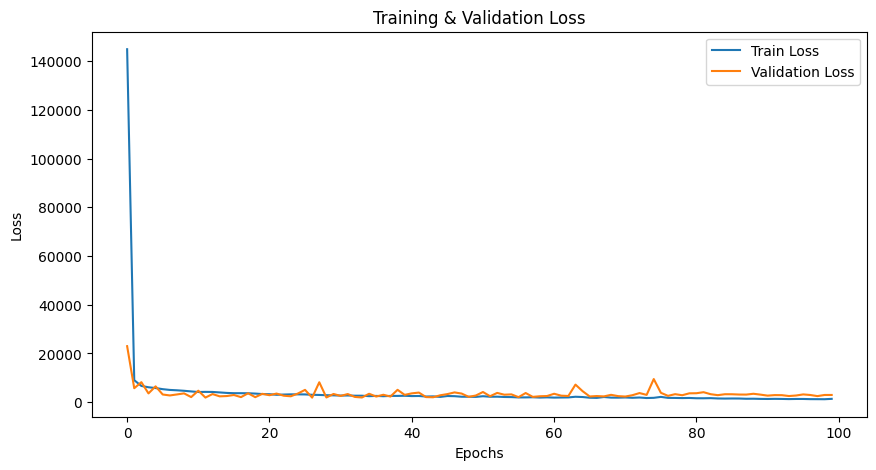

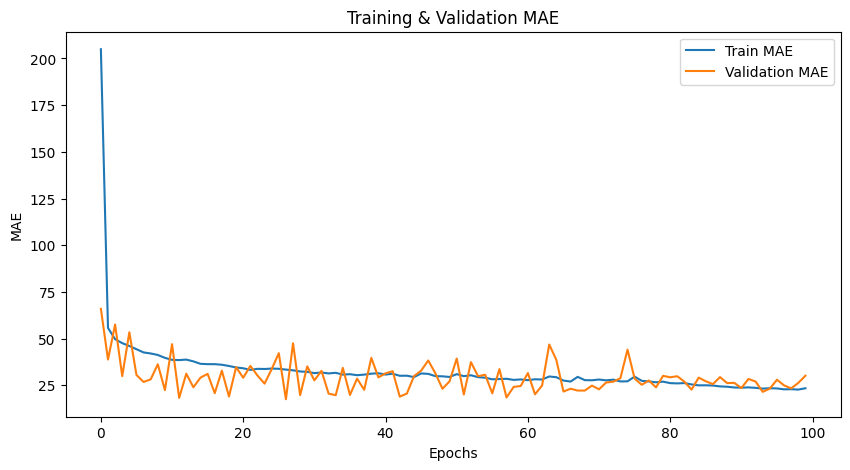

In [8]:
import matplotlib.pyplot as plt

# Plot loss
plt.figure(figsize=(10, 5))
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.legend()
plt.title("Training & Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.show()

# Plot MAE
plt.figure(figsize=(10, 5))
plt.plot(history.history['mae'], label='Train MAE')
plt.plot(history.history['val_mae'], label='Validation MAE')
plt.legend()
plt.title("Training & Validation MAE")
plt.xlabel("Epochs")
plt.ylabel("MAE")
plt.show()


In [9]:
# Make predictions
y_pred = model.predict(X_test)

# Convert predictions to integers (rounding)
y_pred = np.round(y_pred).flatten()

# Show some actual vs predicted values
for i in range(10):
    print(f"Actual: {y_test[i]}, Predicted: {y_pred[i]}")


457/457 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step
Actual: 181, Predicted: 202.0
Actual: 182, Predicted: 202.0
Actual: 183, Predicted: 205.0
Actual: 184, Predicted: 205.0
Actual: 185, Predicted: 204.0
Actual: 186, Predicted: 210.0
Actual: 187, Predicted: 208.0
Actual: 200, Predicted: 210.0
Actual: 189, Predicted: 211.0
Actual: 190, Predicted: 212.0


In [10]:
from tensorflow.keras.layers import Bidirectional

model = Sequential([
    Bidirectional(LSTM(100, return_sequences=True), input_shape=(X_train.shape[1], X_train.shape[2])),
    Dropout(0.2),
    Bidirectional(LSTM(100, return_sequences=False)),
    Dropout(0.2),
    Dense(50, activation='relu'),
    Dense(1)  # Predict stockout days
])

# Compile model
model.compile(optimizer='adam', loss='mse', metrics=['mae'])

# Train the new model
history = model.fit(X_train, y_train, epochs=50, batch_size=32, validation_data=(X_test, y_test), verbose=1)


C:\Users\DELL\AppData\Roaming\Python\Python311\site-packages\keras\src\layers\rnn\bidirectional.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/50
1828/1828 ━━━━━━━━━━━━━━━━━━━━ 31s 13ms/step - loss: 129412.6484 - mae: 183.5416 - val_loss: 4373.6807 - val_mae: 37.7329
Epoch 2/50
1828/1828 ━━━━━━━━━━━━━━━━━━━━ 26s 14ms/step - loss: 4609.3755 - mae: 40.6709 - val_loss: 2867.7673 - val_mae: 27.3521
Epoch 3/50
1828/1828 ━━━━━━━━━━━━━━━━━━━━ 25s 14ms/step - loss: 4282.2183 - mae: 37.9345 - val_loss: 2389.3501 - val_mae: 23.0077
Epoch 4/50
1828/1828 ━━━━━━━━━━━━━━━━━━━━ 25s 14ms/step - loss: 4314.0298 - mae: 38.1076 - val_loss: 4683.3916 - val_mae: 37.1550
Epoch 5/50
1828/1828 ━━━━━━━━━━━━━━━━━━━━ 26s 14ms/step - loss: 3625.9500 - mae: 35.4040 - val_loss: 4231.4541 - val_mae: 33.9647
Epoch 6/50
1828/1828 ━━━━━━━━━━━━━━━━━━━━ 26s 14ms/step - loss: 3488.4082 - mae: 35.1199 - val_loss: 3494.9917 - val_mae: 34.1153
Epoch 7/50
1828/1828 ━━━━━━━━━━━━━━━━━━━━ 25s 14ms/step - loss: 2934.8083 - mae: 33.0892 - val_loss: 3209.9397 - val_mae: 35.6130
Epoch 8/50
1828/1828 ━━━━━━━━━━━━━━━━━━━━ 26s 14ms/step - loss: 3398.0796 - mae: 34.635

In [11]:
# Evaluate on test set
loss, mae = model.evaluate(X_test, y_test, verbose=1)

print(f"✅ Model Evaluation: Loss = {loss}, MAE = {mae}")


457/457 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 1624.8314 - mae: 18.7827
✅ Model Evaluation: Loss = 2007.1376953125, MAE = 21.539833068847656


In [12]:
model.save("inventory_lstm_model.h5")
print("✅ Model saved successfully!")


✅ Model saved successfully!


In [13]:
# Make predictions
y_pred = model.predict(X_test)

# Convert predictions to integers (rounding)
y_pred = np.round(y_pred).flatten()

# Show some actual vs predicted values
for i in range(10):
    print(f"Actual: {y_test[i]}, Predicted: {y_pred[i]}")

457/457 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step
Actual: 181, Predicted: 186.0
Actual: 182, Predicted: 185.0
Actual: 183, Predicted: 185.0
Actual: 184, Predicted: 188.0
Actual: 185, Predicted: 188.0
Actual: 186, Predicted: 188.0
Actual: 187, Predicted: 189.0
Actual: 200, Predicted: 189.0
Actual: 189, Predicted: 203.0
Actual: 190, Predicted: 196.0


In [14]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Make predictions
y_pred = model.predict(X_test)
y_pred = np.round(y_pred).flatten()  # Flatten to match shape

# Calculate metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"✅ Mean Absolute Error (MAE): {mae}")
print(f"✅ Mean Squared Error (MSE): {mse}")
print(f"✅ R² Score: {r2}")


457/457 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step
✅ Mean Absolute Error (MAE): 21.53539913810794
✅ Mean Squared Error (MSE): 2006.7951296258293
✅ R² Score: 0.9931854009628296
